## **Data Wrangling**

Data wrangling is the process of `cleaning`, `transforming`, and `organizing` data so that it can be used for `analysis` and `visualization`. It is an important step in the data analysis process because raw data is often `incomplete`, `inconsistent`, and in an `unstructured format`, which can make it difficult to work with. Data wrangling helps to make the data more `consistent`, `accurate`, and `useful` for analysis and decision-making

#### Steps:
1. Gathering Data - Libraries
2. Tools to Clean Data - Libraries 
3. How to Clean the Data

### **1. Gathering Data**

In [410]:
# import libraries 
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [411]:
df=sns.load_dataset('titanic')
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


### **2. Assessing the Data**

In [412]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [413]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [414]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [415]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


### **3. Cleaning the Data**

#### **a. Dealing with missing values**

In [416]:
(df.isnull().sum()/len(df))*100

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64

In [417]:
# Remove 'deck' column as it contains more than 70% of NaN values
df.drop(columns='deck', inplace=True)

In [418]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone'],
      dtype='str')

In [419]:
df['age']=df.age.fillna(value=df['age'].mean())

In [420]:
df['embarked']=df.embarked.fillna(value=df['embarked'].mode()[0])

In [421]:
df['embark_town']=df.embark_town.fillna(value=df['embark_town'].mode()[0])

In [422]:
(df.isnull().sum()/len(df))*100

survived       0.0
pclass         0.0
sex            0.0
age            0.0
sibsp          0.0
parch          0.0
fare           0.0
embarked       0.0
class          0.0
who            0.0
adult_male     0.0
embark_town    0.0
alive          0.0
alone          0.0
dtype: float64

#### **b. Correcting errors in the data: Outliers Removal**

##### **Visualization method**

<Axes: xlabel='sex', ylabel='age'>

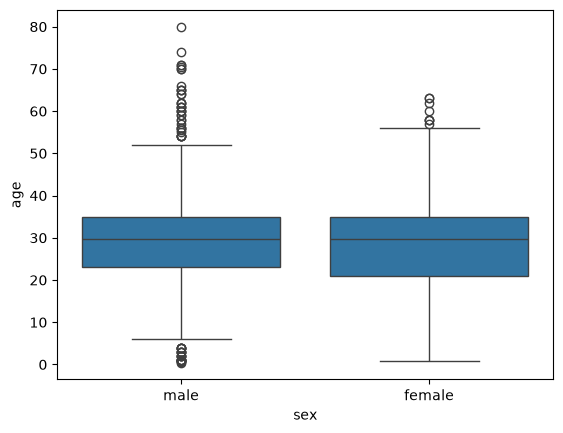

In [423]:
import seaborn as sns
sns.boxplot(data=df, y='age', x='sex')


##### **Inter Quartile Method**

In [424]:
Q1=df['age']. quantile(0.25)
Q3=df['age']. quantile(0.75)
IQR= Q3-Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df = df[(df['age'] >= lower) & (df['age'] <= upper)]


In [425]:
df.shape

(825, 14)

In [426]:
Q1=df['fare']. quantile(0.25)
Q3=df['fare']. quantile(0.75)
IQR= Q3-Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df = df[(df['fare'] >= lower) & (df['fare'] <= upper)]

In [427]:
df.shape

(718, 14)

In [428]:
# Assignment
# Zscore method
from scipy import stats
import numpy as np

zscore = np.abs(stats.zscore(df['age']))
threshold = 3

df = df[(zscore < threshold).all(axis=1)]


AxisError: axis 1 is out of bounds for array of dimension 1

#### **c. Finding and Dropping Duplicates**

In [ ]:
# finding duplicates 
df.duplicated().sum()

np.int64(103)

In [ ]:
# where duplicates are present
df_duplicates=df[df.duplicated()]
df_duplicates.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
47,1,3,female,29.699118,0,0,7.7500,Q,Third,woman,False,Queenstown,yes,True
76,0,3,male,29.699118,0,0,7.8958,S,Third,man,True,Southampton,no,True
77,0,3,male,29.699118,0,0,8.0500,S,Third,man,True,Southampton,no,True
87,0,3,male,29.699118,0,0,8.0500,S,Third,man,True,Southampton,no,True
95,0,3,male,29.699118,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [ ]:
df_duplicates.shape

(103, 14)

In [ ]:
# droping duplicates
df.drop_duplicates(inplace=True)

In [ ]:
df.shape

(615, 14)

### **4. Transforming the Data**

#### **Data Normalization**

To bring data at one scale

In [ ]:
# 1. import libraries
# pip install scikit-learn
import pandas as pd 
from sklearn.preprocessing import MinMaxScaler

# 2. Under-study Data
df

# 3. select columns to normalize
cols_to_normalize= ['age','fare']

# 4. create the scaler function/tool
scaler=MinMaxScaler()

# 5. fit and tranform the data on scalar or vice versa
df[cols_to_normalize]= scaler.fit_transform(df[cols_to_normalize])

# 6. check the data
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,0.372549,1,0,0.118118,S,Third,man,True,Southampton,no,False
2,1,3,female,0.450980,0,0,0.129115,S,Third,woman,False,Southampton,yes,True
3,1,1,female,0.627451,1,0,0.865114,S,First,woman,False,Southampton,yes,False
4,0,3,male,0.627451,0,0,0.131152,S,Third,man,True,Southampton,no,True
5,0,3,male,0.523512,0,0,0.137804,Q,Third,man,True,Queenstown,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,0.470588,0,0,0.211798,S,Second,man,True,Southampton,no,True
887,1,1,female,0.313725,0,0,0.488765,S,First,woman,False,Southampton,yes,True
888,0,3,female,0.523512,1,2,0.382051,S,Third,woman,False,Southampton,no,False
889,1,1,male,0.450980,0,0,0.488765,C,First,man,True,Cherbourg,yes,True


In [ ]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,718.000000,718.000000,718.000000,718.000000,718.000000,718.000000
mean,0.334262,2.512535,0.499270,0.413649,0.317549,0.280114
std,0.472061,0.715818,0.196755,0.855001,0.784792,0.215782
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,0.372549,0.000000,0.000000,0.128538
50%,0.000000,3.000000,0.523512,0.000000,0.000000,0.191433
75%,1.000000,3.000000,0.585784,1.000000,0.000000,0.422426
max,1.000000,3.000000,1.000000,5.000000,6.000000,1.000000


In [ ]:
# 1. import libraries
# pip install scikit-learn
# StandardScaler: range(-3,+3 )
import pandas as pd 
from sklearn.preprocessing import StandardScaler

# 2. Under-study Data
df

# 3. select columns to normalize
cols_to_normalize= ['age','fare']

# 4. create the scaler function/tool
scaler=StandardScaler()

# 5. fit and tranform the data on scalar or vice versa
df[cols_to_normalize]= scaler.fit_transform(df[cols_to_normalize])

# 6. check the data
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,-0.644501,1,0,-0.751265,S,Third,man,True,Southampton,no,False
2,1,3,female,-0.245599,0,0,-0.700265,S,Third,woman,False,Southampton,yes,True
3,1,1,female,0.651930,1,0,2.712961,S,First,woman,False,Southampton,yes,False
4,0,3,male,0.651930,0,0,-0.690821,S,Third,man,True,Southampton,no,True
5,0,3,male,0.123297,0,0,-0.659971,Q,Third,man,True,Queenstown,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,-0.145874,0,0,-0.316820,S,Second,man,True,Southampton,no,True
887,1,1,female,-0.943677,0,0,0.967626,S,First,woman,False,Southampton,yes,True
888,0,3,female,0.123297,1,2,0.472736,S,Third,woman,False,Southampton,no,False
889,1,1,male,-0.245599,0,0,0.967626,C,First,man,True,Cherbourg,yes,True


##### **Log Transformation**

In [449]:
# import dataset
titanic=sns.load_dataset('titanic')
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [ ]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


In [ ]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [429]:
# First do log transformation then remove outliers
import numpy as np

titanic['age']=titanic['age'].fillna(titanic['age'].median())
titanic['fare']=titanic['fare'].fillna(titanic['fare'].median())

# log transform
titanic['age']=np.log(titanic['age']) 
titanic['fare']=np.log(titanic['fare'])
titanic.head()

C:\Users\iTech\AppData\Roaming\Python\Python314\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\iTech\AppData\Roaming\Python\Python314\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,1.128508,1,0,0.683603,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,1.291320,1,0,1.450832,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,1.181143,0,0,0.727559,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,1.268453,1,0,1.379314,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,1.268453,0,0,0.735091,S,Third,man,True,NaN,Southampton,no,True


<Axes: xlabel='sex', ylabel='fare'>

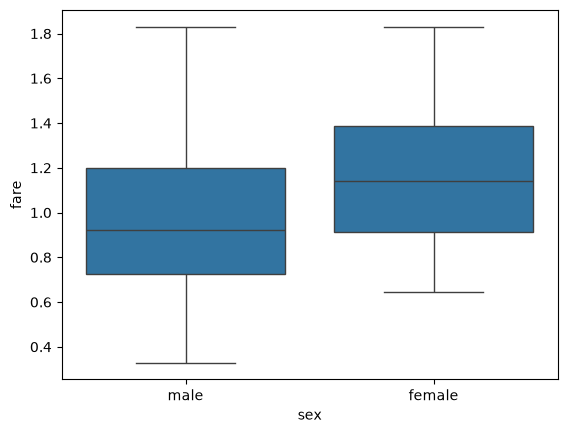

In [430]:
sns.boxplot(data=titanic, x='sex', y='fare')

### **5. Organizing Data**

In [450]:
df['family_size']=df['sibsp']+df['parch']
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,family_size
0,0,3,male,22.000000,1,0,7.2500,S,Third,man,True,Southampton,no,False,1
2,1,3,female,26.000000,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,0
3,1,1,female,35.000000,1,0,53.1000,S,First,woman,False,Southampton,yes,False,1
4,0,3,male,35.000000,0,0,8.0500,S,Third,man,True,Southampton,no,True,0
5,0,3,male,29.699118,0,0,8.4583,Q,Third,man,True,Queenstown,no,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.000000,0,0,13.0000,S,Second,man,True,Southampton,no,True,0
887,1,1,female,19.000000,0,0,30.0000,S,First,woman,False,Southampton,yes,True,0
888,0,3,female,29.699118,1,2,23.4500,S,Third,woman,False,Southampton,no,False,3
889,1,1,male,26.000000,0,0,30.0000,C,First,man,True,Cherbourg,yes,True,0


C:\Users\iTech\AppData\Roaming\Python\Python314\site-packages\seaborn\categorical.py:3399: UserWarning: 17.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


<Axes: xlabel='sex', ylabel='age'>

C:\Users\iTech\AppData\Roaming\Python\Python314\site-packages\seaborn\categorical.py:3399: UserWarning: 21.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\iTech\AppData\Roaming\Python\Python314\site-packages\seaborn\categorical.py:3399: UserWarning: 11.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


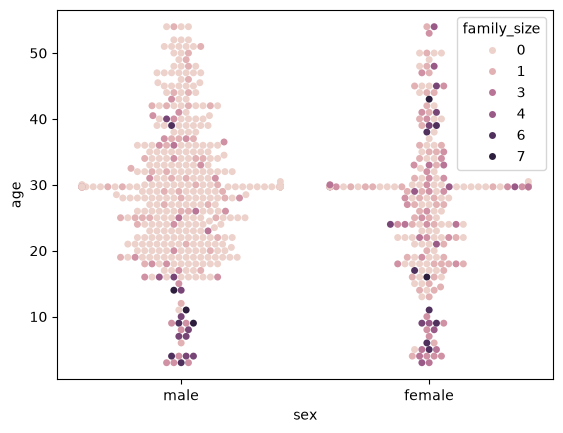

In [453]:
sns.swarmplot(data=df, x='sex',y='age', hue='family_size')

In [454]:
df=df.rename(columns={'survived':'survival'})

In [455]:
df.columns

Index(['survival', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone', 'family_size'],
      dtype='str')

In [465]:
table = pd.pivot_table(df, values='fare', index='who', 
                     columns='survival', aggfunc=np.mean)
table

survival,0,1
who,,
child,28.475336,20.996810
man,13.734053,22.894977
woman,16.608746,21.421291


<Axes: xlabel='fare', ylabel='age'>

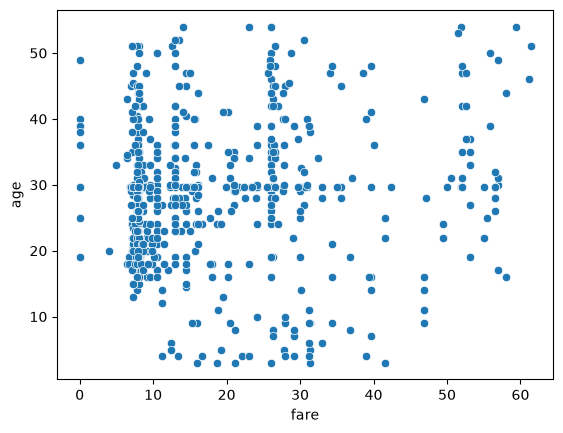

In [467]:
sns.scatterplot(data=df, x='fare', y='age')

#### **6. Saving the Wrangled Data**

In [469]:
df.to_csv('preprocessed_data.csv')